### Después del código proporcionado por el profesor se realizan todas las pruebas

# Introducción a Tensorflow 2


In [1]:
import tensorflow as tf
print(tf.__version__)

2.21.0


## Reproducibilidad

Para poder repetir los experimentos, se fija una semilla al principio.

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Semilla fija para que el modelo salga siempre igual
SEED = 1234
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

## Conjunto de datos
Para comenzar, utilizaremos un clásico conjunto de datos denominado [MNIST](http://yann.lecun.com/exdb/mnist/), formado por un conjunto de imágenes de dígitos manuscritos
![images](https://storage.googleapis.com/tfds-data/visualization/fig/mnist-3.0.1.png)

In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

El conjunto de entrenamiento está formado por 60.000 imágenes de 28x28, mientras que el de test lo forman 10.000 imágenes. El problema de clasificación consiste en distinguir entre los 10 dígitos diferentes

In [4]:
print("Datos de entrenamiento", x_train.shape)
print("Datos de test", x_test.shape)
print("Primeros dígitos: ", y_train[:5])

Datos de entrenamiento (60000, 28, 28)
Datos de test (10000, 28, 28)
Primeros dígitos:  [5 0 4 1 9]


## Pre-procesamiento
Como suele ser habitual, es conveniente realizar algún tipo de procesamiento antes de que los datos sean tratados por el modelo. En este caso, haremos un pequeño procesamiento que consiste en escalar los valores entre 0 y 1. Para ello, bastará con dividir por 255, ya que cada pixel de las imágenes de entrada viene representado por un entero entre 0 y 255 (8 bits) indicando su tonalidad de gris.

In [5]:
x_train = x_train / 255.0 # Importante el .0 para que la división sea decimal
x_test = x_test / 255.0
x_train.dtype

dtype('float64')

## Modelo
Para crear un modelo, primero tenemos que definir la arquitectura neuronal. El caso más sencillo es definir una estructura secuencial de capas, donde la primera actúa de capa de entrada y la última de salida del modelo. Cada capa tendrá una serie de parámetros dependiendo del tipo, habitualmente habrá que especificar el tamaño (número de neuronas), función de activación, etc.

In [6]:
model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28,28)), # La matriz pasa a ser un vector
  tf.keras.layers.Dense(128, activation='relu'), # Capa oculta con 128 neuronas y función de activación ReLU
  tf.keras.layers.Dense(10, activation='softmax') # Una capa de saluda, con 10 neuronas (una por dígito) y función de activación softmax, se activará solamente una, la de mayor potencial
])

c:\Users\usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## Entrenamiento
Antes de entrenar, hay que compilar el modelo indicando:
- La **regla de aprendizaje** (*optimizer*) que define el algoritmo para actualizar los pesos sinápticos de la red
- La **función objetivo** o de pérdida (*loss*), que es optimizada por la regla de aprendizaje
- La **métrica** o medida de evaluación (*metrics*) utilizada para evaluar el modelo entrenado

In [7]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

Tras compilar el modelo, el entrenamiento se define mediante los siguientes parámetros:
- **Épocas** (*epochs*). Número de veces que se le muestra el conjunto de entrenamiento al modelo
- Tamaño de **lote** (*batch_size*). Número de instancias o patrones que se muestran al modelo para actualizar los pesos sinápticos
- Conjunto de **validación** (*validation_spli*). Datos utilizados para medir el rendimiento durante el entrenamiento

En este caso, se ha optado por los valores por defecto

In [8]:
h=model.fit(x_train, y_train, epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9247 - loss: 0.2641
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9668 - loss: 0.1156
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9771 - loss: 0.0782
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9838 - loss: 0.0563
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9887 - loss: 0.0413


## Evaluación
Una vez entrenada la red neuronal, podremos obtener las medidas de rendimiento especificadas en la etapa anterior, tanto para el conjunto de entrenamiento como para el conjunto de test

In [9]:
model.evaluate(x_train, y_train)
model.evaluate(x_test, y_test)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9880 - loss: 0.0388
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9737 - loss: 0.0861


[0.08613334596157074, 0.9736999869346619]

# Estudio de los parámetros de entrenamiento

Se va cambiando un parámetro de entrenamiento cada vez, con el resto en sus valores por defecto, para ver de forma aislada cómo afecta cada uno al modelo. 

Cada entrenamiento reserva un 10% del conjunto de entrenamiento como validación y usa parada temprana, así que se detiene antes si la pérdida de validación deja de mejorar. 

En cada paso se comparan la accuracy, el número de errores, el F1 y el tiempo, y se muestran las matrices de confusión del valor elegido, así como el que peor desempeña. Al final se entrena y evalúa el modelo seleccionado y se sacan las conclusiones globales.

### Funciones de apoyo

In [44]:
def entrenar(neuronas=128, activacion="relu", optimizador="adam",
             perdida="sparse_categorical_crossentropy", epocas=20, lote=32):
    # Reinicializa el modelo con la semilla antes de cada entrenamiento
    tf.keras.utils.set_random_seed(SEED)
    modelo = tf.keras.models.Sequential([
        tf.keras.layers.Flatten(input_shape=(28, 28)),
        tf.keras.layers.Dense(neuronas, activation=activacion),
        tf.keras.layers.Dense(10, activation="softmax"),
    ])
    modelo.compile(optimizer=optimizador, loss=perdida, metrics=["accuracy"])

    # Etiquetas en la forma one hot encoding si la función de pérdida lo necesita
    if perdida in ("categorical_crossentropy", "mean_squared_error", "mean_absolute_error"):
        y_train_fit = tf.keras.utils.to_categorical(y_train, 10)
        y_test_fit = tf.keras.utils.to_categorical(y_test, 10)
    else:
        y_train_fit = y_train
        y_test_fit = y_test

    # Parada temprana vigilando la pérdida de un 10% del entrenamiento usado como validación
    parada = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True)

    inicio = time.time()
    historia = modelo.fit(x_train, y_train_fit, epochs=epocas, batch_size=lote,
                          validation_split=0.1, callbacks=[parada], verbose=0)
    tiempo = time.time() - inicio

    _, acc_train = modelo.evaluate(x_train, y_train_fit, verbose=0)
    _, acc_test = modelo.evaluate(x_test, y_test_fit, verbose=0)

    # Matrices de confusión en entrenamiento y test
    pred_train = np.argmax(modelo.predict(x_train, verbose=0), axis=1)
    pred_test = np.argmax(modelo.predict(x_test, verbose=0), axis=1)
    cm_train = tf.math.confusion_matrix(y_train, pred_train, num_classes=10).numpy()
    cm_test = tf.math.confusion_matrix(y_test, pred_test, num_classes=10).numpy()

    # F1 macro calculado a partir de cada matriz de confusión
    def f1_macro(cm):
        tp = np.diag(cm).astype(float)
        fp = (cm.sum(axis=0) - tp).astype(float)
        fn = (cm.sum(axis=1) - tp).astype(float)
        precision = tp / (tp + fp + 1e-12)
        recall = tp / (tp + fn + 1e-12)
        return float(np.mean(2 * precision * recall / (precision + recall + 1e-12)))

    return {"modelo": modelo, "cm_train": cm_train, "cm_test": cm_test,
            "acc_train": acc_train, "acc_test": acc_test,
            "err_train": int(round((1 - acc_train) * len(y_train))),
            "err_test": int(round((1 - acc_test) * len(y_test))),
            "f1_train": f1_macro(cm_train), "f1_test": f1_macro(cm_test),
            "historia": historia, "tiempo": tiempo}


def dibujar_comparativa(resultados, clave, titulo):
    cortos = {
        "sparse_categorical_crossentropy": "sparse",
        "categorical_crossentropy": "categorical",
        "mean_squared_error": "MSE",
        "mean_absolute_error": "MAE",
    }
    etiquetas = [cortos.get(str(r[clave]), str(r[clave])) for r in resultados]
    fig, ejes = plt.subplots(1, 3, figsize=(10, 3))

    ejes[0].plot(etiquetas, [r["acc_train"] for r in resultados], marker="o", label="Entrenamiento")
    ejes[0].plot(etiquetas, [r["acc_test"] for r in resultados], marker="s", label="Test")
    ejes[0].set_title("Accuracy")
    ejes[0].set_ylim(0.9, 1.01)
    ejes[0].legend(fontsize=8)
    ejes[0].grid(True)

    ejes[1].plot(etiquetas, [r["err_train"] for r in resultados], marker="o", label="Entrenamiento")
    ejes[1].plot(etiquetas, [r["err_test"] for r in resultados], marker="s", label="Test")
    ejes[1].set_title("Número de errores")
    ejes[1].legend(fontsize=8)
    ejes[1].grid(True)

    ejes[2].bar(etiquetas, [r["tiempo"] for r in resultados])
    ejes[2].set_title("Tiempo de entrenamiento (s)")
    ejes[2].grid(True, axis="y")

    larga = max(len(e) for e in etiquetas)
    if larga > 12:
        rotacion, tamano = 45, 6
    elif larga > 4:
        rotacion, tamano = 30, 7
    else:
        rotacion, tamano = 0, 9
    for ax in ejes:
        plt.setp(ax.get_xticklabels(), rotation=rotacion, ha="right" if rotacion else "center", fontsize=tamano)

    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


def dibujar_matrices(resultados, clave):
    # Se dibujan las matrices del mejor y del peor valor según la accuracy en test
    cortos = {"sparse_categorical_crossentropy": "sparse", "categorical_crossentropy": "categorical", "mean_squared_error": "MSE", "mean_absolute_error": "MAE"}
    mejor = max(resultados, key=lambda x: x["acc_test"])
    peor = min(resultados, key=lambda x: x["acc_test"])
    fig, ejes = plt.subplots(1, 4, figsize=(15, 4))
    for i, (r, etiqueta) in enumerate([(mejor, "Mejor"), (peor, "Peor")]):
        for j, (conjunto, cm) in enumerate([("entrenamiento", r["cm_train"]), ("test", r["cm_test"])]):
            ax = ejes[i * 2 + j]
            ax.imshow(cm, cmap="Blues")
            for a in range(10):
                for b in range(10):
                    ax.text(b, a, cm[a, b], ha="center", va="center", fontsize=6,
                            color="white" if cm[a, b] > cm.max() / 2 else "black")
            ax.set_xticks(range(10))
            ax.set_yticks(range(10))
            ax.set_xlabel("Predicho")
            ax.set_ylabel("Real")
            ax.set_title(etiqueta + " (" + cortos.get(str(r[clave]), str(r[clave])) + "), " + conjunto, fontsize=8)
    fig.suptitle("Matrices de confusión del mejor y del peor valor de " + clave)
    plt.tight_layout()
    plt.show()


def dibujar_curvas(configuraciones):
    # configuraciones es una lista de pares (nombre, historia de entrenamiento)
    fig, ejes = plt.subplots(len(configuraciones), 2, figsize=(11, 3.2 * len(configuraciones)), squeeze=False)
    for i, (nombre, h) in enumerate(configuraciones):
        ejes[i, 0].plot(h.history["loss"], marker="o", label="Entrenamiento")
        ejes[i, 0].plot(h.history["val_loss"], marker="s", label="Validación")
        ejes[i, 0].set_title("Pérdida, " + nombre)
        ejes[i, 0].set_xlabel("Época")
        ejes[i, 0].legend(fontsize=8)
        ejes[i, 0].grid(True)
        ejes[i, 1].plot(h.history["accuracy"], marker="o", label="Entrenamiento")
        ejes[i, 1].plot(h.history["val_accuracy"], marker="s", label="Validación")
        ejes[i, 1].set_title("Accuracy, " + nombre)
        ejes[i, 1].set_xlabel("Época")
        ejes[i, 1].legend(fontsize=8)
        ejes[i, 1].grid(True)
    plt.tight_layout()
    plt.show()

### 1. Número de neuronas ocultas

Se cambia solo el número de neuronas de la capa oculta, con el resto en sus valores por defecto.

In [30]:
resultados_neuronas = []
for n in [16, 32, 64, 128, 256]:
    r = entrenar(neuronas=n)
    r["neuronas"] = n
    resultados_neuronas.append(r)

c:\Users\usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


,neuronas,acc_train,acc_test,err_train,err_test,f1_train,f1_test,tiempo
0,16,0.964183,0.9547,2149,453,0.963889,0.954165,36.730292
1,32,0.974083,0.9625,1555,375,0.973914,0.962112,22.292116
2,64,0.987450,0.9731,753,269,0.987498,0.972928,28.021065
3,128,0.986233,0.9767,826,233,0.986189,0.976611,20.933513
4,256,0.990483,0.9787,571,213,0.990471,0.978542,30.914860


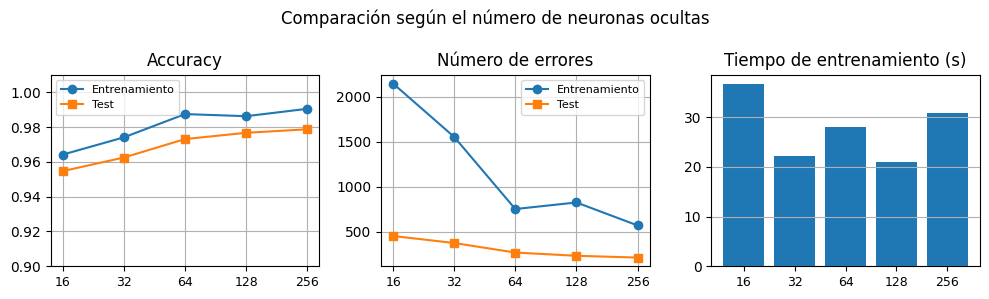

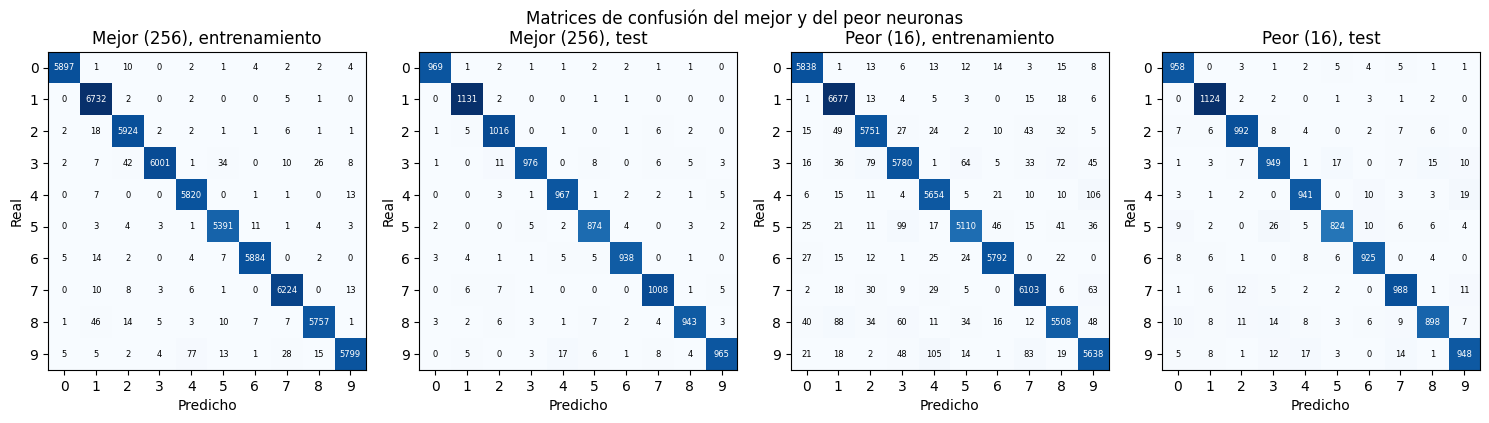

In [31]:
tabla = pd.DataFrame(resultados_neuronas)[["neuronas", "acc_train", "acc_test", "err_train", "err_test", "f1_train", "f1_test", "tiempo"]]
display(tabla)
dibujar_comparativa(resultados_neuronas, "neuronas", "Comparación según el número de neuronas ocultas")
dibujar_matrices(resultados_neuronas, "neuronas")

Con 16 neuronas la capa oculta no tiene capacidad suficiente para separar las 10 clases y se cometen 453 errores en test, el peor resultado de todo el estudio. Al pasar a 32 y 64 los errores bajan a 375 y 269, y con 128 se llega a 233. La mejora es grande al principio y se va agotando, porque las primeras neuronas son las que aportan capacidad nueva y las siguientes apenas cambian la frontera de decisión.

Podría parecer incoherente el tiempo que tarda en ejecutarse para 16 neuronas, pero el tiempo aquí no mide una época, sino el entrenamiento entero hasta que la parada temprana lo corta, así que cada valor corre un número distinto de épocas. Con 16 neuronas la validación baja despacio y la parada tarda en dispararse, de modo que aprovecha casi todas las 20 épocas y acaba siendo el más lento, con 37 segundos, mientras que 128 y 256 ajustan antes y se cortan en menos épocas. Por eso 16 no solo pierde en test, además cuesta más tiempo.

De 128 a 256 solo se ganan 20 errores en test, mientras el entrenamiento sube a 0.9905 y el hueco con el test se abre más. Es un caso de sobreajuste, el modelo mejora en los datos que ve pero ya no generaliza mejor. Encaja con el compromiso de sesgo contra varianza, más neuronas reducen el sesgo pero suben la varianza. La matriz de confusión lo deja ver, los errores se concentran en parejas de dígitos que comparten trazos, como el 4 con el 9 o el 3 con el 5 y el 8.

Se eligen 128 neuronas porque la diferencia con 256 en test es de solo 20 errores y entra dentro del ruido, mientras que 256 tiene el doble de parámetros, tarda 31 segundos frente a los 21 de 128 y abre más el hueco con el entrenamiento. Es el mejor equilibrio entre precisión, coste y generalización, y además es la opción con la que parte el resto del estudio.

### 2. Función de activación de la capa oculta

Se cambia solo la función de activación de la capa oculta, con el resto en sus valores por defecto.

In [13]:
resultados_activaciones = []
for a in ["relu", "tanh", "sigmoid", "leaky_relu"]:
    r = entrenar(activacion=a)
    r["activación"] = a
    resultados_activaciones.append(r)

c:\Users\usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


,activación,acc_train,acc_test,err_train,err_test,f1_train,f1_test,tiempo
0,relu,0.986233,0.9767,826,233,0.986189,0.976611,20.262778
1,tanh,0.991367,0.9765,518,235,0.991350,0.976305,28.640851
2,sigmoid,0.993983,0.9772,361,228,0.993989,0.977057,44.111404
3,leaky_relu,0.986617,0.9740,803,260,0.986547,0.973786,26.566812


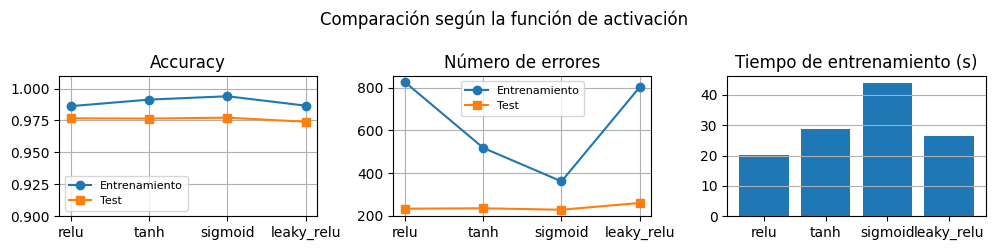

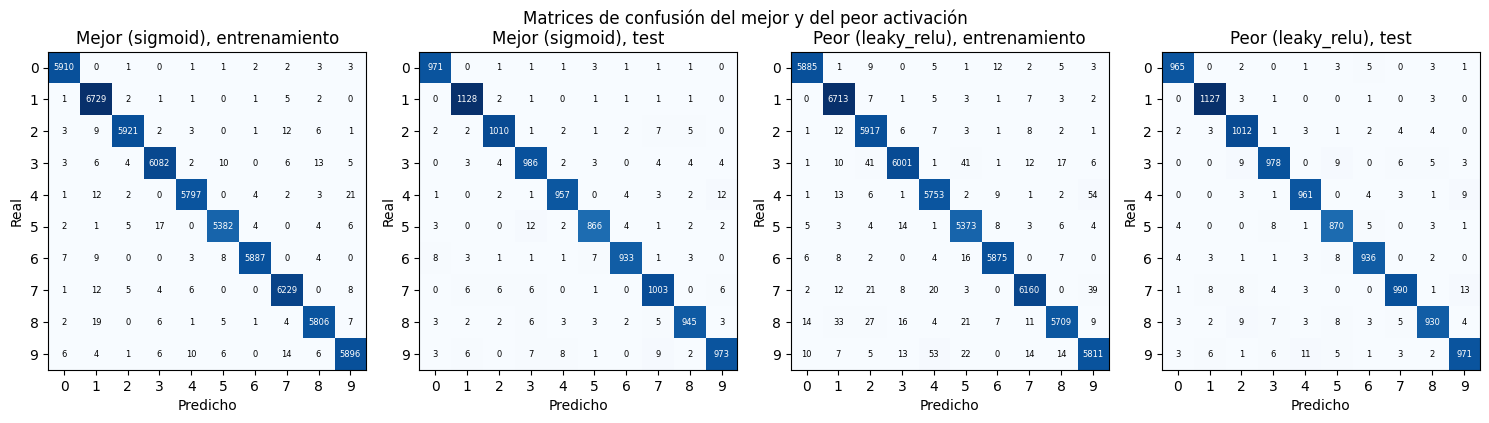

In [14]:
tabla = pd.DataFrame(resultados_activaciones)[["activación", "acc_train", "acc_test", "err_train", "err_test", "f1_train", "f1_test", "tiempo"]]
display(tabla)
dibujar_comparativa(resultados_activaciones, "activación", "Comparación según la función de activación")
dibujar_matrices(resultados_activaciones, "activación")

Las cuatro funciones quedan muy igualadas en test, sigmoide 0.9772, relu 0.9767, tanh 0.9765 y leaky_relu 0.9740, y esa diferencia es tan pequeña que se puede considerar ruido. Lo que sí cambia mucho es el coste, relu tarda 20 segundos frente a los 44 de la sigmoide.

Teóricamente relu debería ser la mejor opción con diferencia porque no se satura en los valores positivos y su derivada vale 1, así que el gradiente llega completamente a las capas de atrás. La tanh también va bien porque está centrada en cero, pero satura en los extremos. La sigmoide satura en los dos lados y su derivada máxima es 0.25, así que el gradiente se va apagando al propagarse hacia atrás, y por eso es la más lenta aunque su accuracy sea parecida. La leaky_relu deja pasar un poco de gradiente en los negativos, pero con este problema no aporta nada y queda por debajo.

Se escoge relu, que empata en precisión con el resto, converge igual de rápido que la mejor y es la más barata de entrenar.
 Las matrices confirman que las cuatro cometen el mismo tipo de error, con la diagonal muy marcada y unos pocos cruces entre dígitos de trazo parecido, sobre todo el 4 con el 9 en la sigmoide y el 7 con el 9 en la leaky_relu.

### 3. Algoritmo de optimización

Se prueban las cuatro vistas en clase y aparte el SGD con momento: el descenso por gradiente estocástico, su versión con momento, el gradiente adaptativo, la propagación por raíz del error cuadrático medio y la estimación adaptativa del momento, con el resto de parámetros en sus valores por defecto.

In [32]:
optimizadores = {
    "SGD": lambda: tf.keras.optimizers.SGD(learning_rate=0.01),
    "SGD momento": lambda: tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "Adagrad": lambda: tf.keras.optimizers.Adagrad(learning_rate=0.01),
    "RMSprop": lambda: tf.keras.optimizers.RMSprop(learning_rate=0.001),
    "Adam": lambda: tf.keras.optimizers.Adam(learning_rate=0.001),
}
resultados_optimizadores = []
for nombre in optimizadores:
    r = entrenar(optimizador=optimizadores[nombre]())
    r["optimizador"] = nombre
    resultados_optimizadores.append(r)

c:\Users\usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


,optimizador,acc_train,acc_test,err_train,err_test,f1_train,f1_test,tiempo
0,SGD,0.970050,0.9644,1797,356,0.969888,0.964069,46.912125
1,SGD momento,0.991733,0.9761,496,239,0.991746,0.975993,33.151011
2,Adagrad,0.978150,0.9714,1311,286,0.978042,0.971202,56.570371
3,RMSprop,0.985033,0.9735,898,265,0.984940,0.973349,22.497503
4,Adam,0.986233,0.9767,826,233,0.986189,0.976611,20.801810


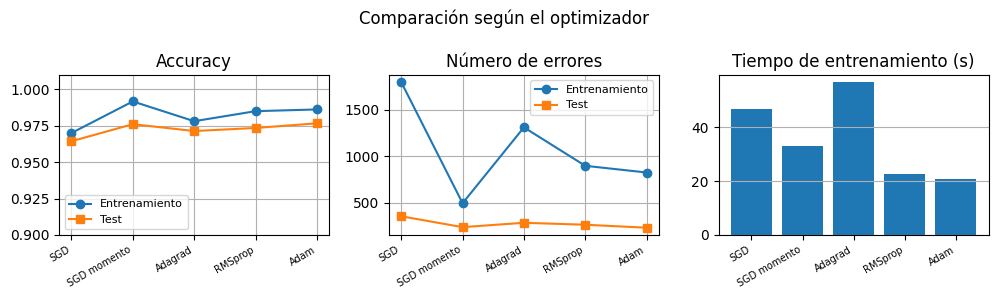

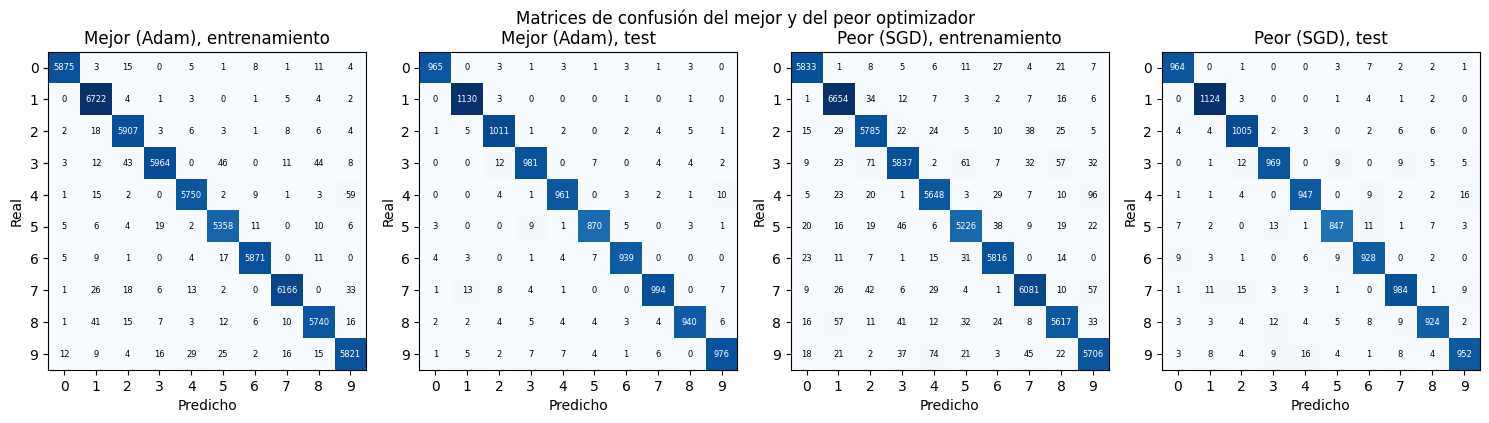

In [33]:
tabla = pd.DataFrame(resultados_optimizadores)[["optimizador", "acc_train", "acc_test", "err_train", "err_test", "f1_train", "f1_test", "tiempo"]]
display(tabla)
dibujar_comparativa(resultados_optimizadores, "optimizador", "Comparación según el optimizador")
dibujar_matrices(resultados_optimizadores, "optimizador")

El SGD básico aplica el mismo paso a todos los pesos con una tasa fija. Es simple, pero avanza lento y con tan pocas épocas de margen se queda en 0.9644, el peor del estudio.

El SGD con momento guarda una media de los gradientes anteriores y se mueve con ella. Eso acelera en las direcciones constantes y suaviza las fluctuaciones, y con eso se pone en 0.9761, ya al nivel de los adaptativos. Adagrad ajusta la tasa de cada peso dividiendo por la suma de sus gradientes al cuadrado, así que los pesos con gradientes grandes dan pasos pequeños y los pequeños dan pasos grandes. El problema es que esa suma solo crece, la tasa se va apagando y se queda en 0.9714.

RMSprop corrige eso con una media exponencial de los gradientes recientes, de modo que la tasa se adapta a lo que pasa ahora y no se apaga, y sube a 0.9735. Adam combina las dos ideas, el momento y la tasa adaptativa con corrección de sesgo, y es el mejor, con 0.9767. Los adaptativos aprenden más rápido en pocas épocas a cambio de un poco más de cómputo por paso, y eso se ve en que Adagrad y el SGD básico, que no adaptan igual de bien, se quedan atrás.

Todo es coherente, los tres métodos que mejor ajustan la tasa por peso, Adam, momento y RMSprop, son los que mejor generalizan, y Adam es además el más estable porque corrige el sesgo de las primeras iteraciones. Se elige Adam.
 En las matrices, con Adam la diagonal está muy marcada y los 233 errores se van sobre todo al 7 confundido con el 1 y al 4 con el 9, mientras que el SGD del peor caso, con 356 errores, suma otros cruces como el 7 con el 2 y el 5 con el 3.

### 4. Tamaño de lote

Se cambia solo el tamaño de lote, con el resto en sus valores por defecto.

In [17]:
resultados_lotes = []
for b in [16, 32, 64, 128, 256]:
    r = entrenar(lote=b)
    r["batch size"] = b
    resultados_lotes.append(r)

c:\Users\usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


,batch size,acc_train,acc_test,err_train,err_test,f1_train,f1_test,tiempo
0,16,0.983817,0.9741,971,259,0.983741,0.973994,33.189368
1,32,0.986233,0.9767,826,233,0.986189,0.976611,21.036294
2,64,0.985783,0.9728,853,272,0.985786,0.972718,13.882261
3,128,0.991433,0.9758,514,242,0.991433,0.975686,13.970183
4,256,0.990983,0.9757,541,243,0.990963,0.975500,10.499243


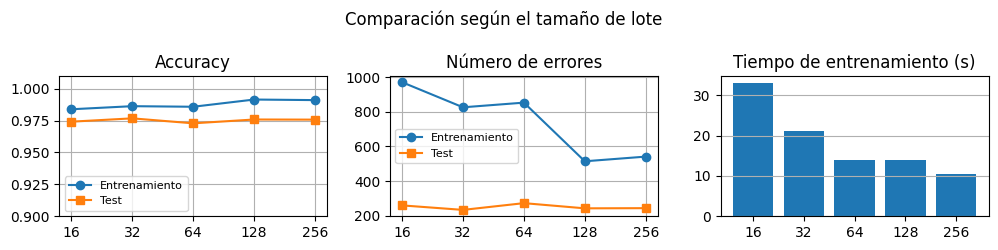

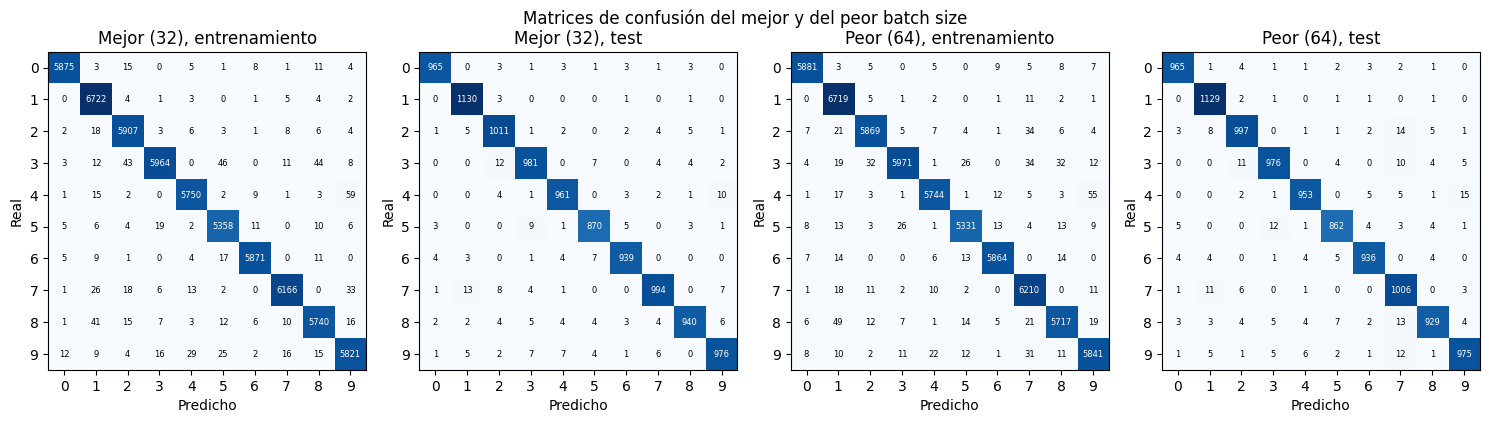

In [18]:
tabla = pd.DataFrame(resultados_lotes)[["batch size", "acc_train", "acc_test", "err_train", "err_test", "f1_train", "f1_test", "tiempo"]]
display(tabla)
dibujar_comparativa(resultados_lotes, "batch size", "Comparación según el tamaño de lote")
dibujar_matrices(resultados_lotes, "batch size")

El tamaño de lote decide cuántas actualizaciones se hacen por época y cuánto ruido lleva cada gradiente. Con lote 16 hay muchas actualizaciones por época, pero cada gradiente es muy ruidoso, el resultado en test baja a 0.9741 y el tiempo sube a 33 segundos. Un lote muy pequeño obliga a más cómputo por época y no compensa.

Con 32 se obtiene el mejor test, 0.9767, y con 128 y 256 la accuracy se queda muy cerca, 0.9758 y 0.9757, pero entrenando bastante más rápido, 13 y 10 segundos. El lote 64 se queda algo por debajo, 0.9728, lo que demuestra que la variación entre valores consecutivos es pequeña y está dentro del ruido.

En teoría, el número de actualizaciones por época es el tamaño del conjunto entre el del lote. Un lote grande da un gradiente más fiable y épocas más rápidas, pero hace menos actualizaciones, mientras que el pequeño hace muchas pero con mucha varianza. El ruido del gradiente estocástico regulariza, así que los lotes muy grandes tienden a generalizar algo peor con el mismo número de épocas. Lo observado es coherente, el mejor equilibrio está en un lote intermedio.

Se elige 32, que da el mejor test y coincide con el valor por defecto. 128 y 256 quedan muy cerca y son más rápidos, pero a costa de una diferencia en test que no es significativa.
 Las dos matrices son muy parecidas y con la diagonal dominante, aunque la del lote 64, el peor, deja algo más de cruce en el 3 con el 7 y el 4 con el 9.

### 5. Número de épocas

Se cambia solo el número de épocas, con el resto en sus valores por defecto.

In [19]:
resultados_epocas = []
for e in [1, 2, 5, 10, 20]:
    r = entrenar(epocas=e)
    r["epochs"] = e
    resultados_epocas.append(r)

c:\Users\usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


,epochs,acc_train,acc_test,err_train,err_test,f1_train,f1_test,tiempo
0,1,0.961000,0.9583,2340,417,0.960663,0.957858,3.764341
1,2,0.975817,0.9698,1451,302,0.975665,0.969589,6.606173
2,5,0.986233,0.9767,826,233,0.986189,0.976611,15.306157
3,10,0.986233,0.9767,826,233,0.986189,0.976611,21.385658
4,20,0.986233,0.9767,826,233,0.986189,0.976611,21.385585


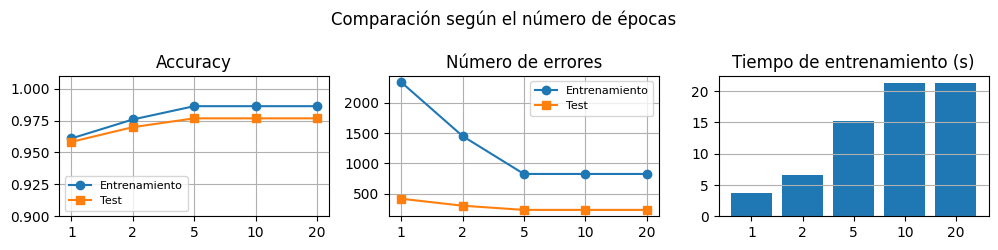

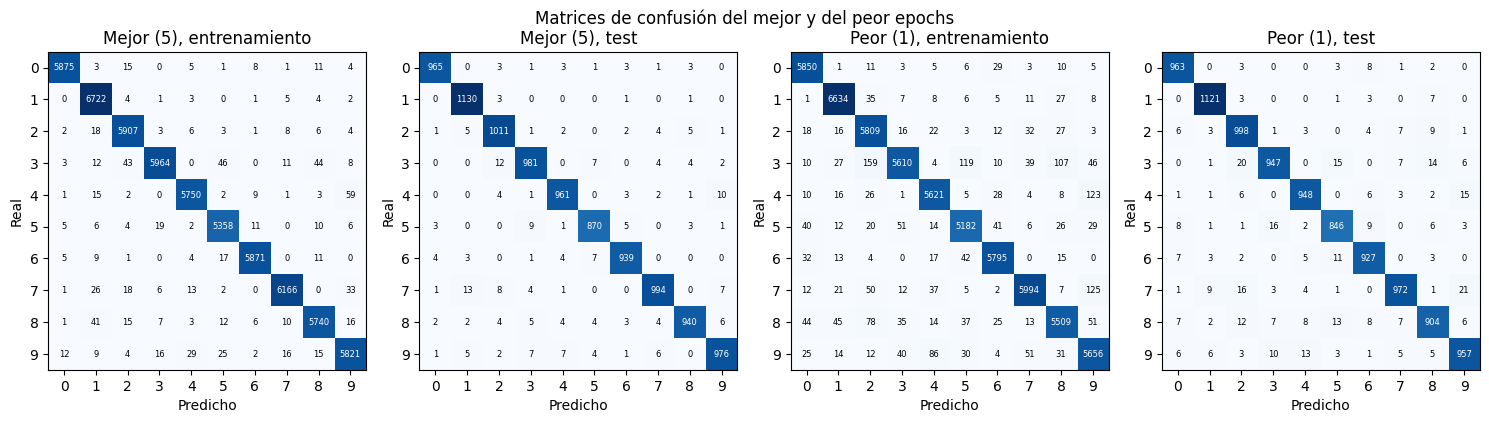

In [20]:
tabla = pd.DataFrame(resultados_epocas)[["epochs", "acc_train", "acc_test", "err_train", "err_test", "f1_train", "f1_test", "tiempo"]]
display(tabla)
dibujar_comparativa(resultados_epocas, "epochs", "Comparación según el número de épocas")
dibujar_matrices(resultados_epocas, "epochs")

Con una sola época el modelo no ha ajustado sus pesos y se queda en 0.9583, con 417 errores. Con 2 épocas sube a 0.9698 y con 5 a 0.9767, la mejora es grande al principio y luego se agota.

A partir de 5 épocas el resultado se congela, 10 y 20 épocas dan el mismo valor, 0.9767. Esto ocurre porque entra en juego la parada temprana que se ha implementado. Con 20 épocas disponibles, el modelo deja de mejorar la pérdida de validación y se detiene y recupera los mejores pesos con el mismo ajuste que a las 5 épocas. El sobreajuste queda así controlado, porque el entrenamiento no sigue insistiendo cuando ya no aporta.

Es coherente con la lógica del sobreajuste, que aparece cuando el entrenamiento sigue mejorando y la validación se estanca, y aquí el callback lo corta antes de que ocurra. La curva de aprendizaje del apartado de monitorización lo confirma. Se eligen 5 épocas, que ya alcanzan el máximo de calidad sin gastar tiempo de más.
 En la matriz del peor caso, con una sola época y 417 errores, se abren cruces más gordos, como el 3 con el 2 y el 5 con el 3, que con 5 épocas bajan y dejan la diagonal bastante más limpia.

### 6. Función de pérdida

Se prueba la entropía cruzada para etiquetas dispersas, la entropía cruzada categórica con etiquetas en one-hot y el error cuadrático medio, con el resto de parámetros en sus valores por defecto.

In [34]:
resultados_perdidas = []
for p in ["sparse_categorical_crossentropy", "categorical_crossentropy", "mean_squared_error", "mean_absolute_error"]:
    r = entrenar(perdida=p)
    r["pérdida"] = p
    resultados_perdidas.append(r)

c:\Users\usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


,pérdida,acc_train,acc_test,err_train,err_test,f1_train,f1_test,tiempo
0,sparse_categorical_crossentropy,0.986233,0.9767,826,233,0.986189,0.976611,23.116706
1,categorical_crossentropy,0.986233,0.9767,826,233,0.986189,0.976611,24.155556
2,mean_squared_error,0.984350,0.9754,939,246,0.984323,0.975260,67.300037
3,mean_absolute_error,0.989433,0.9766,634,234,0.989443,0.976476,164.226302


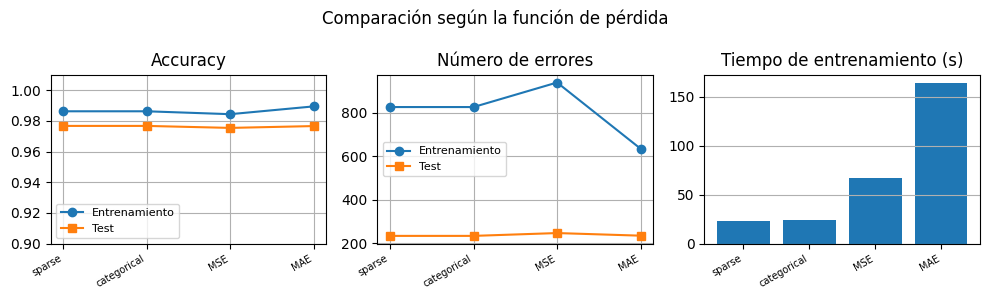

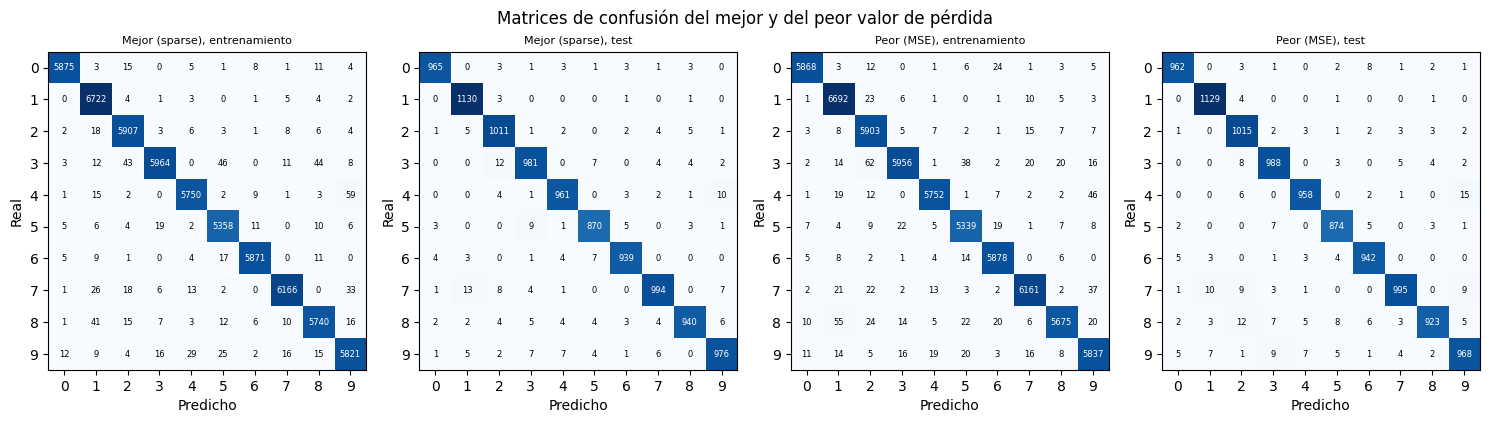

In [38]:
tabla = pd.DataFrame(resultados_perdidas)[["pérdida", "acc_train", "acc_test", "err_train", "err_test", "f1_train", "f1_test", "tiempo"]]
display(tabla)
dibujar_comparativa(resultados_perdidas, "pérdida", "Comparación según la función de pérdida")
dibujar_matrices(resultados_perdidas, "pérdida")

Las dos entropías cruzadas dan el mismo resultado porque son la misma función, solo cambia el formato de la etiqueta, que pasa de entero a one-hot, que es dedicar una vector de posiciones binarias a cada clase. La única diferencia es el tiempo, la categórica es algo más lenta porque hay que convertir las etiquetas.

El error cuadrático medio queda en 0.9754 y el error absoluto medio en 0.9766, prácticamente lo mismo que la entropía cruzada, pero el absoluto tarda mucho más, 164 segundos frente a los 23, porque su gradiente es más débil y necesita más trabajo por paso.

La explicación teórica es que la entropía cruzada es la pérdida propia de clasificación, mide el desorden entre la distribución predicha y la real, penaliza las predicciones seguras y equivocadas y su gradiente no se satura con softmax. El error cuadrático trata las 10 salidas como una regresión y, combinado con softmax, su gradiente se apaga cuando la salida se acerca a 0 o a 1, por eso cuesta más ajustar. Coherente con que la entropía cruzada sea la más rápida en converger y la más barata.

Se elige la entropía cruzada para etiquetas dispersas, que es igual de precisa, más barata que la categórica y la adecuada para el problema.
 Las matrices del mejor y del peor caso son casi iguales, con la diagonal fuerte y los fallos en los mismos dígitos parecidos, sobre todo el 4 con el 9, coherente con que solo las separen 13 errores.

### 7. Tasa de aprendizaje

Se cambia solo la tasa de aprendizaje del optimizador Adam, con el resto en sus valores por defecto.

In [23]:
resultados_lr = []
for lr in [0.0001, 0.001, 0.01, 0.1]:
    r = entrenar(optimizador=tf.keras.optimizers.Adam(learning_rate=lr))
    r["learning rate"] = lr
    resultados_lr.append(r)

c:\Users\usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


,learning rate,acc_train,acc_test,err_train,err_test,f1_train,f1_test,tiempo
0,0.0001,0.983233,0.9731,1006,269,0.983176,0.972915,65.243503
1,0.0010,0.986233,0.9767,826,233,0.986189,0.976611,23.775316
2,0.0100,0.964333,0.9586,2140,414,0.963917,0.958087,16.361901
3,0.1000,0.601017,0.5988,23939,4012,0.637175,0.635588,26.483305


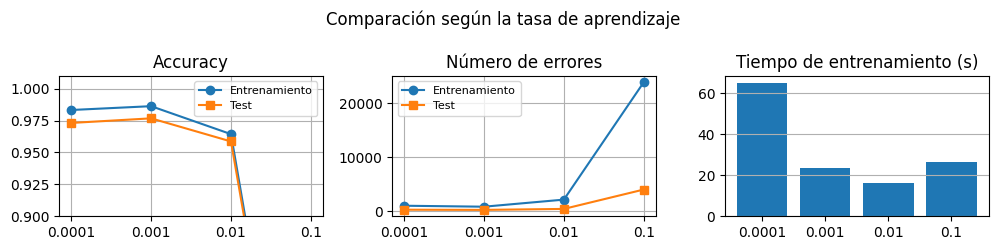

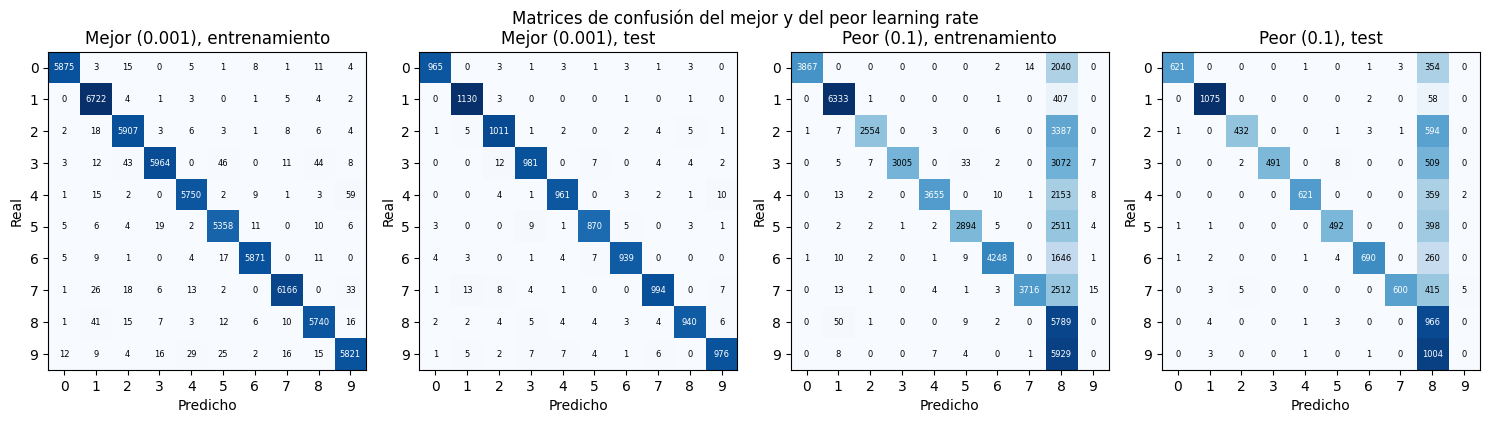

In [24]:
tabla = pd.DataFrame(resultados_lr)[["learning rate", "acc_train", "acc_test", "err_train", "err_test", "f1_train", "f1_test", "tiempo"]]
display(tabla)
dibujar_comparativa(resultados_lr, "learning rate", "Comparación según la tasa de aprendizaje")
dibujar_matrices(resultados_lr, "learning rate")

Con una tasa de 0.1 el accuracy se hunde a 0.5988, con 4012 errores, el peor resultado de todo el cuaderno. Los pasos son tan grandes que el optimizador se pasa continuamente del mínimo y el modelo no llega a converger, incluso con 20 épocas de margen. Con 0.01 ya se queda en 0.9586, todavía por debajo, señal de que sigue siendo demasiado grande.

Con 0.0001 el aprendizaje es demasiado lento, el modelo avanza con pasos muy pequeños y con las pocas épocas disponibles no le da tiempo a ajustar bien, se queda en 0.9731. Con 0.001 se llega al mejor resultado, 0.9767, y además en 24 segundos, que es el menor tiempo entre las tasas que convergen bien, porque necesita menos épocas y la parada temprana lo corta antes.

Es coherente con el papel de la tasa de aprendizaje, que escala el tamaño del paso en la dirección del gradiente. Si es muy grande el paso se pasa y el entrenamiento diverge, si es muy pequeña el paso se queda corto y el aprendizaje es lento. El óptimo está en el término medio. Se elige 0.001, que es además el valor por defecto de Adam.
 La matriz del peor caso, la tasa 0.1, está rota, con las predicciones desplomadas hacia unas pocas columnas, sobre todo la del 8, que se lleva casi todos los 9 y buena parte de los 0, 2, 3, 4, 5 y 6. Con 0.001 la diagonal concentra casi todos los aciertos.

### 8. Mejor configuración y guardado del modelo

In [39]:
mejor_neuronas = 128
mejor_activacion = "relu"
mejor_optimizador = "Adam"
mejor_lote = 32
mejor_epocas = 5
mejor_perdida = "sparse_categorical_crossentropy"
mejor_learning_rate = 0.001

print("Mejor configuración elegida:")
print("  neuronas ocultas:", mejor_neuronas)
print("  activación:", mejor_activacion)
print("  optimizador:", mejor_optimizador)
print("  batch size:", mejor_lote)
print("  epochs:", mejor_epocas)
print("  pérdida:", mejor_perdida)
print("  learning rate:", mejor_learning_rate)

Mejor configuración elegida:
  neuronas ocultas: 128
  activación: relu
  optimizador: Adam
  batch size: 32
  epochs: 5
  pérdida: sparse_categorical_crossentropy
  learning rate: 0.001


c:\Users\usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


,acc_train,acc_test,err_train,err_test,f1_train,f1_test,tiempo
0,0.986233,0.9767,826,233,0.986189,0.976611,20.220228


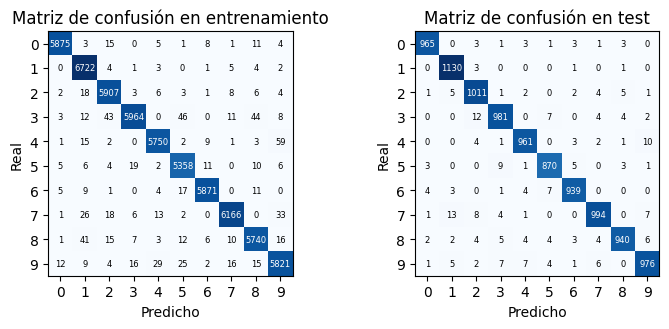

In [45]:
final = entrenar(neuronas=mejor_neuronas, activacion=mejor_activacion,
                 optimizador=tf.keras.optimizers.Adam(learning_rate=mejor_learning_rate),
                 perdida=mejor_perdida, epocas=mejor_epocas, lote=mejor_lote)

tabla_final = pd.DataFrame([{
    "acc_train": final["acc_train"],
    "acc_test": final["acc_test"],
    "err_train": final["err_train"],
    "err_test": final["err_test"],
    "f1_train": final["f1_train"],
    "f1_test": final["f1_test"],
    "tiempo": final["tiempo"],
}])
display(tabla_final)

fig, ejes = plt.subplots(1, 2, figsize=(7.5, 3.4))
for ax, nombre, cm in [(ejes[0], "entrenamiento", final["cm_train"]), (ejes[1], "test", final["cm_test"])]:
    ax.imshow(cm, cmap="Blues")
    for i in range(10):
        for j in range(10):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
    ax.set_title("Matriz de confusión en " + nombre)
plt.tight_layout()
plt.show()

In [41]:
# Se guarda el mejor modelo en disco para poder usarlo más adelante
final["modelo"].save("mejor_modelo.keras")
print("Modelo guardado en mejor_modelo.keras")

Modelo guardado en mejor_modelo.keras


### 9. Curvas de aprendizaje

Para ver cómo aprende por dentro el modelo se dibujan la pérdida y la accuracy de entrenamiento y de validación en cada época del modelo final.

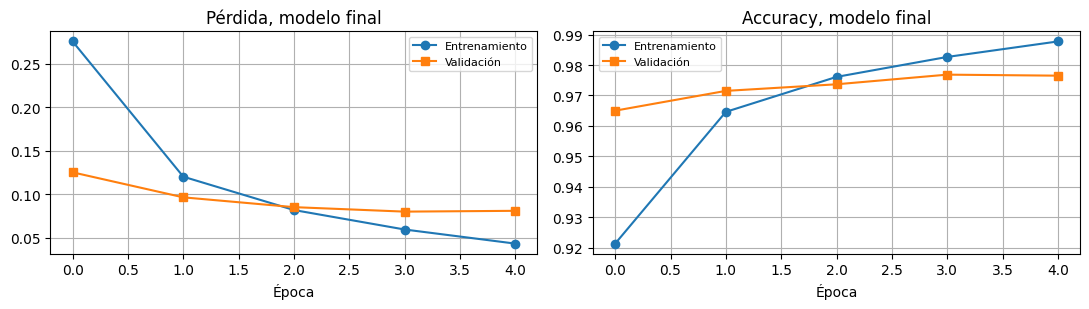

In [46]:
dibujar_curvas([
    ("modelo final", final["historia"]),
])

### 10. Conclusiones

La mejor configuración es 128 neuronas ocultas, activación ReLU, Adam con tasa 0.001, lote 32, 5 épocas y entropía cruzada para etiquetas dispersas. Es la que mejor equilibra precisión, generalización y coste. Aunque 256 neuronas y la sigmoide dan el mejor test absoluto, 256 solo gana 20 errores a cambio del doble de parámetros y más sobreajuste, y la sigmoide mejora por 0.0005, que es ruido, tardando casi el doble. El modelo se guarda en `mejor_modelo.keras` para poder reutilizarlo sin volver a entrenar.